<a href="https://colab.research.google.com/github/Aarushi-Srivastava-07/Attendance-Tracker/blob/main/Unit_3_MLflow_Simple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unit 3: Unsupervised Learning with MLflow

**Algorithms:** K-Means Clustering, Gaussian Mixture Model (GMM), and Factor Analysis.


## Block 0: Install libraries

In [ ]:
%pip install -q mlflow scikit-learn pandas numpy matplotlib seaborn joblib

## Block 1: Import libraries

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow
import mlflow.sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import FactorAnalysis
from sklearn.metrics import silhouette_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

np.random.seed(42)
OUTPUT_DIR = "/content/unit3_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries imported")

Libraries imported


## Block 2: Upload and read the dataset

In [ ]:
from google.colab import files

if not os.path.exists("/content/Unit 3.csv"):
    files.upload()

df = pd.read_csv("/content/Unit 3.csv")
print("Dataset shape:", df.shape)
display(df.head())

Saving Unit 3.csv to Unit 3.csv
Dataset shape: (1642, 11)


,Location,Address,Period,Maximum Temperature,Minimum Temperature,Temperature,Heat Index,Precipitation,Wind Speed,Cloud Cover,Relative Humidity
0,"Karjat, MH, India","Karjat, MH, India",Week 1 (Jan) 2000,33.1,17.5,25.4,32.3,0.0,14.8,0.3,48.93
1,"Karjat, MH, India","Karjat, MH, India",Week 2 (Jan) 2000,33.1,11.2,24.8,32.0,0.0,18.4,2.4,42.30
2,"Karjat, MH, India","Karjat, MH, India",Week 3 (Jan) 2000,31.1,11.2,24.3,31.9,0.0,22.3,5.5,57.20
3,"Karjat, MH, India","Karjat, MH, India",Week 4 (Jan) 2000,37.1,17.2,26.3,39.4,0.0,22.3,7.6,53.69
4,"Karjat, MH, India","Karjat, MH, India",Week 5 (Jan) 2000,34.1,17.3,25.9,32.8,0.0,18.4,1.1,44.75


## Block 3: Clean data and select features

In [ ]:
features = [
    "Maximum Temperature", "Minimum Temperature", "Temperature",
    "Heat Index", "Precipitation", "Wind Speed", "Cloud Cover",
    "Relative Humidity"
]

# Make sure the selected columns contain numbers.
df[features] = df[features].apply(pd.to_numeric, errors="coerce")
df = df.dropna(subset=features).reset_index(drop=True)

X = df[features]
periods = df["Period"]

print("Clean records:", len(X))
print("Features:", len(features))
print("Missing values:", X.isna().sum().sum())

Clean records: 1642
Features: 8
Missing values: 0


## Block 4: Split training/testing data and scale it

In [ ]:
# Keep earlier weeks for training and later weeks for testing.
split = int(len(X) * 0.80)
X_train = X.iloc[:split]
X_test = X.iloc[split:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

periods_test = periods.iloc[split:].reset_index(drop=True)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Last training period:", periods.iloc[split - 1])
print("First testing period:", periods.iloc[split])

Training records: 1313
Testing records: 329
Last training period: Week 42 (Oct) 1995
First testing period: Week 43 (Oct) 1995


## Block 5: Create a simple reference for comparison

The original notebook compares clusters with a label made from whether Temperature is above its training median. This is only a **proxy reference**, not a real weather category or ground-truth label. We use it only for demonstration metrics.

In [ ]:
temperature_limit = X_train["Temperature"].median()
y_train = (X_train["Temperature"] > temperature_limit).astype(int).to_numpy()
y_test = (X_test["Temperature"] > temperature_limit).astype(int).to_numpy()

print("Training temperature median:", temperature_limit)
print("Training proxy labels:", np.bincount(y_train, minlength=2))
print("Testing proxy labels:", np.bincount(y_test, minlength=2))

Training temperature median: 27.5
Training proxy labels: [663 650]
Testing proxy labels: [254  75]


## Block 6: K-Means Clustering

K-Means groups similar observations into two clusters. It learns from training data and assigns clusters to the testing data.

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_train = kmeans.fit_predict(X_train_scaled)
kmeans_test = kmeans.predict(X_test_scaled)

# Cluster numbers are arbitrary. Choose the better of the two possible mappings.
same_score = np.sum((kmeans_train == y_train))
flip_score = np.sum((1 - kmeans_train) == y_train)
if same_score >= flip_score:
    kmeans_test_aligned = kmeans_test
else:
    kmeans_test_aligned = 1 - kmeans_test

if len(np.unique(kmeans_test)) > 1:
    kmeans_silhouette = silhouette_score(X_test_scaled, kmeans_test)
else:
    kmeans_silhouette = 0.0

kmeans_accuracy = accuracy_score(y_test, kmeans_test_aligned)
kmeans_precision = precision_score(y_test, kmeans_test_aligned, zero_division=0)
kmeans_recall = recall_score(y_test, kmeans_test_aligned, zero_division=0)
kmeans_f1 = f1_score(y_test, kmeans_test_aligned, zero_division=0)

print("K-Means test silhouette:", round(kmeans_silhouette, 4))
print("Proxy accuracy:", round(kmeans_accuracy, 4))
print("Proxy precision:", round(kmeans_precision, 4))
print("Proxy recall:", round(kmeans_recall, 4))
print("Proxy F1:", round(kmeans_f1, 4))

K-Means test silhouette: 0.3816
Proxy accuracy: 0.6018
Proxy precision: 0.3133
Proxy recall: 0.6267
Proxy F1: 0.4178


## Block 7: Gaussian Mixture Model (GMM)

GMM groups observations using Gaussian probability distributions. It also gives the probability that each observation belongs to each cluster.

In [ ]:
gmm = GaussianMixture(n_components=2, covariance_type="full", random_state=42)
gmm.fit(X_train_scaled)

gmm_train = gmm.predict(X_train_scaled)
gmm_test = gmm.predict(X_test_scaled)
gmm_probabilities = gmm.predict_proba(X_test_scaled)

same_score = np.sum(gmm_train == y_train)
flip_score = np.sum((1 - gmm_train) == y_train)
if same_score >= flip_score:
    gmm_test_aligned = gmm_test
else:
    gmm_test_aligned = 1 - gmm_test

if len(np.unique(gmm_test)) > 1:
    gmm_silhouette = silhouette_score(X_test_scaled, gmm_test)
else:
    gmm_silhouette = 0.0

gmm_accuracy = accuracy_score(y_test, gmm_test_aligned)
gmm_precision = precision_score(y_test, gmm_test_aligned, zero_division=0)
gmm_recall = recall_score(y_test, gmm_test_aligned, zero_division=0)
gmm_f1 = f1_score(y_test, gmm_test_aligned, zero_division=0)

print("GMM converged:", gmm.converged_)
print("GMM test silhouette:", round(gmm_silhouette, 4))
print("Proxy accuracy:", round(gmm_accuracy, 4))
print("Proxy precision:", round(gmm_precision, 4))
print("Proxy recall:", round(gmm_recall, 4))
print("Proxy F1:", round(gmm_f1, 4))

GMM converged: True
GMM test silhouette: 0.3514
Proxy accuracy: 0.5471
Proxy precision: 0.2016
Proxy recall: 0.3333
Proxy F1: 0.2513


## Block 8: Factor Analysis

Factor Analysis reduces the eight observed weather features into two underlying factors. It is a dimensionality-reduction method, not a clustering algorithm.

In [ ]:
factor_model = FactorAnalysis(n_components=2, random_state=42)
train_factors = factor_model.fit_transform(X_train_scaled)
test_factors = factor_model.transform(X_test_scaled)

factor_score = factor_model.score(X_test_scaled)
loadings = pd.DataFrame(
    factor_model.components_.T,
    index=features,
    columns=["Factor_1", "Factor_2"]
)

print("Original features:", X_train_scaled.shape[1])
print("Reduced factors:", test_factors.shape[1])
print("Test average log-likelihood:", round(factor_score, 4))
display(loadings)

Original features: 8
Reduced factors: 2
Test average log-likelihood: -7.8408


,Factor_1,Factor_2
Maximum Temperature,-0.517295,0.675936
Minimum Temperature,-0.737756,-0.468272
Temperature,-0.993989,0.033026
Heat Index,-0.816494,-0.126475
Precipitation,-0.024476,-0.619254
Wind Speed,-0.156054,-0.147044
Cloud Cover,-0.231277,-0.904590
Relative Humidity,-0.118310,-0.922111


## Block 9: Compare algorithm results

,Algorithm,Test Silhouette,Proxy Accuracy,Proxy Precision,Proxy Recall,Proxy F1
0,K-Means,0.381574,0.601824,0.313333,0.626667,0.417778
1,GMM,0.351444,0.547112,0.201613,0.333333,0.251256


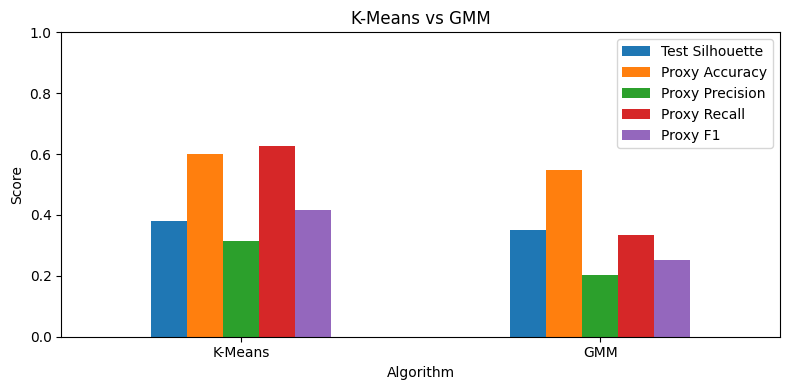

In [ ]:
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "GMM"],
    "Test Silhouette": [kmeans_silhouette, gmm_silhouette],
    "Proxy Accuracy": [kmeans_accuracy, gmm_accuracy],
    "Proxy Precision": [kmeans_precision, gmm_precision],
    "Proxy Recall": [kmeans_recall, gmm_recall],
    "Proxy F1": [kmeans_f1, gmm_f1]
})

display(comparison)
comparison.set_index("Algorithm").plot(kind="bar", ylim=(0, 1), figsize=(8, 4))
plt.title("K-Means vs GMM")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
comparison_plot = OUTPUT_DIR + "/clustering_comparison.png"
plt.savefig(comparison_plot)
plt.show()

## Block 10: Confusion matrices and Factor Analysis graph

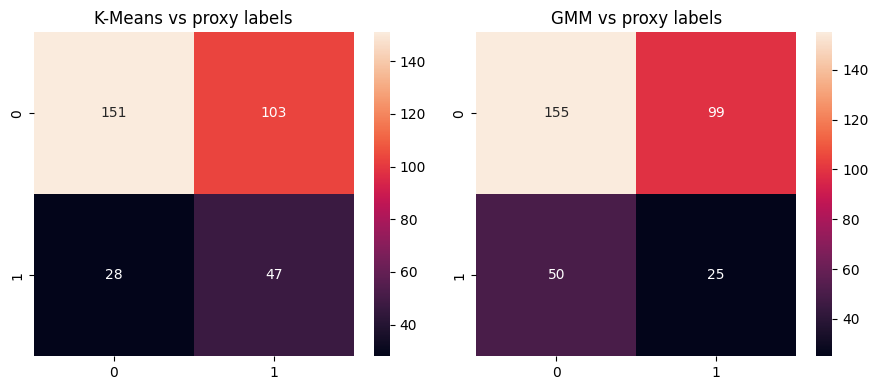

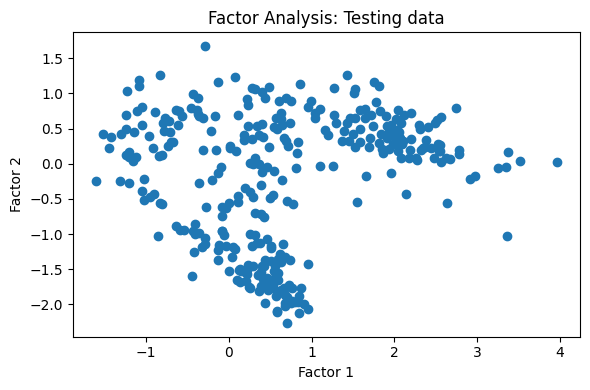

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
sns.heatmap(confusion_matrix(y_test, kmeans_test_aligned), annot=True, fmt="d", ax=axes[0])
axes[0].set_title("K-Means vs proxy labels")
sns.heatmap(confusion_matrix(y_test, gmm_test_aligned), annot=True, fmt="d", ax=axes[1])
axes[1].set_title("GMM vs proxy labels")
plt.tight_layout()
confusion_plot = OUTPUT_DIR + "/confusion_matrices.png"
plt.savefig(confusion_plot)
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(test_factors[:, 0], test_factors[:, 1])
plt.xlabel("Factor 1")
plt.ylabel("Factor 2")
plt.title("Factor Analysis: Testing data")
plt.tight_layout()
factor_plot = OUTPUT_DIR + "/factor_analysis.png"
plt.savefig(factor_plot)
plt.show()

## Block 11: Save results and models

In [ ]:
results = pd.DataFrame({
    "Period": periods_test,
    "Temperature": X_test["Temperature"].to_numpy(),
    "Temperature_Proxy": y_test,
    "KMeans_Cluster": kmeans_test,
    "GMM_Cluster": gmm_test,
    "GMM_Probability_0": gmm_probabilities[:, 0],
    "GMM_Probability_1": gmm_probabilities[:, 1],
    "Factor_1": test_factors[:, 0],
    "Factor_2": test_factors[:, 1]
})

results_file = OUTPUT_DIR + "/unit3_test_results.csv"
loadings_file = OUTPUT_DIR + "/factor_loadings.csv"
comparison_file = OUTPUT_DIR + "/clustering_metrics.csv"
models_file = OUTPUT_DIR + "/unit3_models.joblib"

results.to_csv(results_file, index=False)
loadings.to_csv(loadings_file)
comparison.to_csv(comparison_file, index=False)
joblib.dump({"scaler": scaler, "kmeans": kmeans, "gmm": gmm, "factor_model": factor_model}, models_file)

print("Saved results, loadings, metrics and trained models.")
display(results.head())

Saved results, loadings, metrics and trained models.


,Period,Temperature,Temperature_Proxy,KMeans_Cluster,GMM_Cluster,GMM_Probability_0,GMM_Probability_1,Factor_1,Factor_2
0,Week 43 (Oct) 1995,26.8,0,0,0,0.997409,2.591221e-03,0.196749,-0.341225
1,Week 44 (Oct) 1995,26.9,0,1,0,1.000000,2.510840e-07,0.187628,0.411646
2,Week 45 (Nov) 1995,25.1,0,1,0,1.000000,1.511871e-12,1.044335,0.721723
3,Week 46 (Nov) 1995,24.7,0,1,0,1.000000,7.503232e-13,1.199775,0.409464
4,Week 47 (Nov) 1995,24.0,0,1,0,1.000000,2.323592e-17,1.526651,0.653070


## Block 12: Set up MLflow

In [ ]:
MLFLOW_DB = "sqlite:////content/mlflow_unit3.db"
ARTIFACTS = "/content/mlflow_unit3_artifacts"
os.makedirs(ARTIFACTS, exist_ok=True)

mlflow.set_tracking_uri(MLFLOW_DB)
mlflow.set_experiment("Unit_3_Unsupervised_Learning")

print("MLflow version:", mlflow.__version__)
print("Experiment: Unit_3_Unsupervised_Learning")

2026/11/19 07:28:42 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 07:28:42 INFO mlflow.store.db.utils: Updating database tables
2026/11/19 07:28:46 INFO mlflow.tracking.fluent: Experiment with name 'Unit_3_Unsupervised_Learning' does not exist. Creating a new experiment.


MLflow version: 3.18.0
Experiment: Unit_3_Unsupervised_Learning


## Block 13: Track the three algorithms in MLflow

Each algorithm gets its own run. The common parameters are logged in each run, along with its metrics and relevant files.

In [ ]:
import mlflow

mlflow.set_tracking_uri(MLFLOW_DB)
mlflow.set_experiment("Unit_3_Unsupervised_Learning")

common = {
    "dataset": "Unit 3.csv",
    "train_records": len(X_train),
    "test_records": len(X_test),
    "features": len(features),
    "split": "80:20 chronological",
    "clusters_or_factors": 2
}

# RUN 1: K-Means
with mlflow.start_run(run_name="KMeans_Clustering"):
    mlflow.log_params(common)
    mlflow.log_param("algorithm", "KMeans")
    mlflow.log_metric("test_silhouette", kmeans_silhouette)
    mlflow.log_metric("proxy_accuracy", kmeans_accuracy)
    mlflow.log_metric("proxy_precision", kmeans_precision)
    mlflow.log_metric("proxy_recall", kmeans_recall)
    mlflow.log_metric("proxy_f1", kmeans_f1)

    mlflow.log_artifact(results_file)
    mlflow.log_artifact(comparison_plot)
    mlflow.sklearn.log_model(kmeans, artifact_path="kmeans_model")

# RUN 2: Gaussian Mixture Model
with mlflow.start_run(run_name="Gaussian_Mixture_Model"):
    mlflow.log_params(common)
    mlflow.log_param("algorithm", "GaussianMixture")
    mlflow.log_metric("test_silhouette", gmm_silhouette)
    mlflow.log_metric("proxy_accuracy", gmm_accuracy)
    mlflow.log_metric("proxy_precision", gmm_precision)
    mlflow.log_metric("proxy_recall", gmm_recall)
    mlflow.log_metric("proxy_f1", gmm_f1)

    mlflow.log_artifact(results_file)
    mlflow.log_artifact(confusion_plot)
    mlflow.sklearn.log_model(gmm, artifact_path="gmm_model")

# RUN 3: Factor Analysis
with mlflow.start_run(run_name="Factor_Analysis"):
    mlflow.log_params(common)
    mlflow.log_param("algorithm", "FactorAnalysis")
    mlflow.log_metric("test_average_log_likelihood", factor_score)

    mlflow.log_artifact(loadings_file)
    mlflow.log_artifact(factor_plot)
    mlflow.sklearn.log_model(
        factor_model, artifact_path="factor_analysis_model"
    )

print("SUCCESS: All three algorithm runs logged!")

2026/11/19 07:28:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 07:28:57 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 07:29:02 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 07:29:02 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!


SUCCESS: All three algorithm runs logged!


## Block 14: Check MLflow runs

In [ ]:
experiment = mlflow.get_experiment_by_name("Unit_3_Unsupervised_Learning")
runs = mlflow.search_runs(experiment_ids=[experiment.experiment_id])

print("Experiment ID:", experiment.experiment_id)
print("Number of runs:", len(runs))
display(runs[["tags.mlflow.runName", "status"]])

expected = ["KMeans_Clustering", "Gaussian_Mixture_Model", "Factor_Analysis"]
actual = runs["tags.mlflow.runName"].tolist()

for name in expected:
    print(name, "FOUND" if name in actual else "MISSING")

Experiment ID: 1
Number of runs: 3


,tags.mlflow.runName,status
0,Factor_Analysis,FINISHED
1,Gaussian_Mixture_Model,FINISHED
2,KMeans_Clustering,FINISHED


KMeans_Clustering FOUND
Gaussian_Mixture_Model FOUND
Factor_Analysis FOUND


## Block 15: Start the MLflow dashboard (optional)

Run this after MLflow logging. Keep the Colab runtime open while viewing the dashboard.

In [ ]:

import os
import sys
import time
import subprocess
import requests
import mlflow
from google.colab import output

# Stop the previous Unit 3 MLflow server, if running
try:
    if mlflow_server.poll() is None:
        mlflow_server.terminate()
        mlflow_server.wait(timeout=10)
        print("Previous Unit 3 server stopped.")
except (NameError, Exception):
    print("No previous server to stop.")

# IMPORTANT: Keep the existing Unit 3 database
DB = "sqlite:////content/mlflow_unit3.db"
ARTIFACTS = "/content/mlflow_unit3_artifacts"
os.makedirs(ARTIFACTS, exist_ok=True)

# Start MLflow server using the same configuration as Rice HMM
server_log = open("/content/unit3_server.log", "w")

mlflow_server = subprocess.Popen(
    [
        sys.executable, "-m", "mlflow", "server",
        "--host", "0.0.0.0",
        "--port", "5001",
        "--backend-store-uri", DB,
        "--default-artifact-root", ARTIFACTS,
        "--allowed-hosts", "*",
        "--cors-allowed-origins", "*"
    ],
    stdout=server_log,
    stderr=subprocess.STDOUT
)

LOCAL_URL = "http://127.0.0.1:5001"

# Wait until MLflow is ready
ready = False

for _ in range(40):
    try:
        response = requests.get(LOCAL_URL + "/health", timeout=3)
        if response.status_code == 200:
            ready = True
            break
    except requests.RequestException:
        pass
    time.sleep(2)

if not ready:
    server_log.flush()
    print(open("/content/unit3_server.log").read()[-5000:])
    raise RuntimeError("Unit 3 MLflow server failed to start.")

# Connect to Unit 3 tracking database
mlflow.set_tracking_uri(LOCAL_URL)
mlflow.set_experiment("Unit_3_Unsupervised_Learning")

# Open the Colab dashboard
dashboard_url = output.eval_js(
    "google.colab.kernel.proxyPort(5001)"
)

print("===================================")
print("UNIT 3 MLFLOW SERVER STARTED")
print("===================================")
print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment: Unit_3_Unsupervised_Learning")
print("Dashboard:", dashboard_url)


No previous server to stop.
UNIT 3 MLFLOW SERVER STARTED
MLflow version: 3.18.0
Tracking URI: http://127.0.0.1:5001
Experiment: Unit_3_Unsupervised_Learning
Dashboard: https://5001-m-s-euw4b9-hl3hlc9aiwhn-b.europe-west4.prod.r.colab.dev
